# ESS 배터리 수명 예측 — DAY2
**이름: 김도현** · 작성일: 2026-10-02

초기 100사이클로 최종 `cycle_life`를 예측하는 회귀 프로젝트입니다.
노션 지침: **Batch 1 학습 → Batch 1 hold-out 검증 → Batch 2 최종 평가**.
동일 모델로 Batch 3 추가 평가도 합니다. 주지표는 MAPE이고 과제 비교 기준은 9.1%입니다.

실행: `pip install -r requirements.txt` 후 **Run All**. 포함된 셀별 피처 CSV로 재현할 수 있습니다.
원본으로 다시 추출하려면 `data/README.md`를 참고하세요. 실행하면 프로젝트 내부 `results/`를 갱신합니다.
DAY1의 셀 수·라벨과 차이가 있어 DAY2는 원본 MAT만을 기준으로 통일했습니다.


In [1]:
from pathlib import Path
import sys, os, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    raise RuntimeError('노트북이 있는 ESS-Battery-DAY2 폴더에서 실행하세요.')
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.mplconfig'))
from src.features import build_features, CORE, EXTENDED
from src.train import run_training
from src.plots import make_figures
from src.diagnostics import diagnose
print('Python:', sys.version.split()[0])

Python: 3.11.15


## 1. 데이터와 품질 점검
배터리 셀 하나가 표의 한 행입니다. 입력은 cycle 2–100의 summary와 `Q100(V)-Q10(V)`뿐입니다.
1사이클은 일부 배치의 0 placeholder를 피하기 위해 공통 제외합니다.
수명 라벨 결측 셀은 지도학습·평가에서 제외하고 목록을 `cell_audit.csv`에 기록합니다.
전체 길이·마지막 용량·미래 knee point 등은 입력에 사용하지 않습니다.


In [2]:
REBUILD_FEATURES = False
RAW_DIR = ROOT / 'data/raw'
if REBUILD_FEATURES:
    build_features(RAW_DIR, ROOT / 'data/processed')
features = pd.read_csv(ROOT / 'data/processed/features.csv')
audit = pd.read_csv(ROOT / 'data/processed/cell_audit.csv')
display(audit.groupby('batch').agg(전체_셀=('cell_uid','size'), 사용_셀=('included','sum')))
display(audit.loc[~audit.included, ['cell_uid','cycle_life','reason']])
display(features[EXTENDED].isna().sum().rename('missing'))
assert features.cell_uid.is_unique
assert (features.cycle_life > 100).all()
print('분석 표:', features.shape)

분석 표: (129, 17)


,전체_셀,사용_셀
batch,,
B1,46,46
B2,47,39
B3,46,44


,cell_uid,cycle_life,reason
68,B2C22,NaN,missing_or_nonpositive_life_after_cycle100
69,B2C23,NaN,missing_or_nonpositive_life_after_cycle100
81,B2C35,NaN,missing_or_nonpositive_life_after_cycle100
82,B2C36,NaN,missing_or_nonpositive_life_after_cycle100
83,B2C37,NaN,missing_or_nonpositive_life_after_cycle100
84,B2C38,NaN,missing_or_nonpositive_life_after_cycle100
85,B2C39,NaN,missing_or_nonpositive_life_after_cycle100
86,B2C40,NaN,missing_or_nonpositive_life_after_cycle100
116,B3C23,NaN,missing_or_nonpositive_life_after_cycle100
125,B3C32,NaN,missing_or_nonpositive_life_after_cycle100


log_dq_var        0
log_abs_dq_min    0
qd_slope          0
ir_mean           6
charge_mean       0
qd_initial        0
qd_delta          0
ir_delta          6
temp_mean         0
c1                0
q1                0
c2                0
Name: missing, dtype: int64

## 2. DAY1에서 이어지는 모델 전략
Delta Q의 로그 분산은 초기 방전 곡선의 변화를 요약합니다. 소표본이므로 1피처 선형 모델부터 비교합니다.
Core 피처는 Delta Q 2개, QD 기울기, IR 평균, 충전 시간 평균이며, Extended는 초기 용량·변화량·온도·충전 조건을 더합니다.
상관관계가 높은 피처에는 Ridge/ElasticNet 규제를 사용하고, 비선형 후보는 Gradient Boosting입니다.

**실험 규칙을 먼저 고정합니다.** B1의 충전 정책 그룹 20%를 seed=42로 hold-out하고,
나머지 B1에서 바깥 5-fold / 안쪽 최대 4-fold GroupKFold를 수행합니다.
같은 정책은 fold 양쪽에 들어가지 않습니다. 안쪽에서 하이퍼파라미터를 고르고 바깥 MAPE 평균으로 모델을 비교합니다.
결측치 대체·표준화는 각 학습 fold에서만 fit하며, 수명은 log10 변환 후 학습하고 원래 사이클 단위로 되돌려 평가합니다.

후보 선택에 따른 낙관 편향은 여전히 남으므로, 최종 B1 hold-out과 B2 평가를 따로 보고합니다.
이 노트북은 B2/B3 성능을 보고 모델을 다시 선택하지 않습니다.


In [3]:
summary, comparison, performance = run_training(
    ROOT / 'data/processed/features.csv', ROOT / 'results')
display(comparison.round(3))
print('선택 모델:', summary['model'])
print('최종 하이퍼파라미터:', summary['params'])
print('학습/검증 셀 수:', summary['train_n'], summary['valid_n'])
print('학습/검증 정책 수:', summary['train_protocols'], summary['valid_protocols'])

DummyMedian: nested grouped CV MAPE 19.76%
LogLinear_DeltaQ: nested grouped CV MAPE 7.00%
Ridge_Core: nested grouped CV MAPE 9.28%
ElasticNet_Core: nested grouped CV MAPE 9.05%
ElasticNet_Extended: nested grouped CV MAPE 6.66%
GradientBoosting_Core: nested grouped CV MAPE 11.23%
                   Index  MAPE_or_Gap Unit                                                   Note
      Train (Batch 1 CV)     6.656799    % B1 train only; mean of 5 nested GroupKFold outer folds
Valid (Batch 1 Hold-out)    16.480086    %              11 cells; unseen charging-protocol groups
          Test (Batch 2)   124.985883    %               Frozen B1-training model; no test tuning
       Gap (Train-Valid)     9.823287   pp         Valid minus CV; positive means error increased
        Gap (Valid-Test)   108.505796   pp       Test minus Valid; positive means error increased
       Gap (Target-Test)   115.885883   pp                      Test minus assignment target 9.1%
      External (Batch 3)    14.527

,model,n_features,CV_MAPE_mean_pct,CV_MAPE_sd_pp
0,ElasticNet_Extended,12,6.657,0.602
1,LogLinear_DeltaQ,1,7.000,2.199
2,ElasticNet_Core,5,9.050,1.647
3,Ridge_Core,5,9.279,1.506
4,GradientBoosting_Core,5,11.230,4.431
5,DummyMedian,5,19.759,8.833


## 3. 최종 성능과 GAP
동일하게 고정된 B1 학습 부분집합 모델로 Valid, B2, B3를 평가합니다.
hold-out까지 재학습하지 않아 세 성능의 비교 기준이 일관됩니다.
Train 항목은 재학습 오차가 아니라 **B1 학습 부분집합의 바깥 CV 평균**입니다.

MAPE는 `mean(abs(y-pred)/y) × 100`입니다. GAP은 퍼센트포인트(pp)입니다.
노션 표의 (+)=오차 악화 해석에 맞춰 Train-Valid는 **Valid−CV**,
Valid-Test는 **Test−Valid**, Target-Test는 **Test−9.1**로 계산합니다.
표 제목의 하이픈을 산술 뺄셈으로 해석하면 부호가 반대가 되므로 계산식을 명시했습니다.

9.1%는 과제 지정 비교값입니다. 현재 데이터 파일·셀 구성·배치 분할은 논문의 원래 실험과 달라 엄밀한 논문 재현 점수는 아닙니다.


,Index,MAPE_or_Gap,Unit,Note
0,Train (Batch 1 CV),6.657,%,B1 train only; mean of 5 nested GroupKFold out...
1,Valid (Batch 1 Hold-out),16.480,%,11 cells; unseen charging-protocol groups
2,Test (Batch 2),124.986,%,Frozen B1-training model; no test tuning
3,Gap (Train-Valid),9.823,pp,Valid minus CV; positive means error increased
4,Gap (Valid-Test),108.506,pp,Test minus Valid; positive means error increased
5,Gap (Target-Test),115.886,pp,Test minus assignment target 9.1%
6,External (Batch 3),14.528,%,Same frozen model; optional external evaluation
7,Gap (Batch2-Batch3),-110.458,pp,Batch3 minus Batch2


,split,n,MAPE_pct,MAE_cycles,RMSE_cycles,R2
0,Valid (Batch 1 Hold-out),11,16.480,163.423,216.851,-0.315
1,Test (Batch 2),39,124.986,680.250,1061.016,-22.401
2,External (Batch 3),44,14.528,183.970,281.256,0.178


,count,mean,median,min,max
batch,,,,,
B1,46,844.7,858.5,534.0,1227.0
B2,39,565.7,472.0,392.0,1186.0
B3,44,1059.7,1005.5,541.0,1935.0


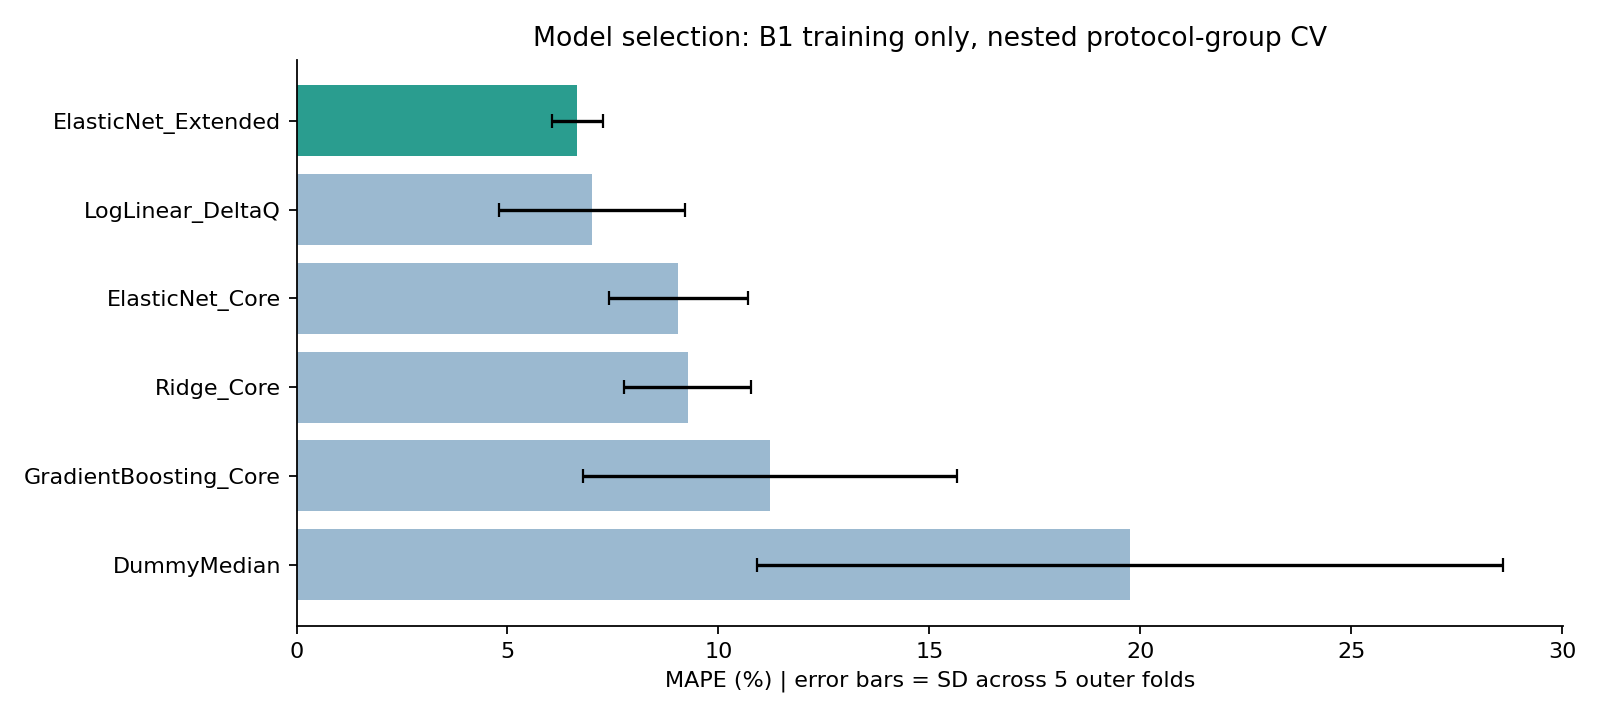

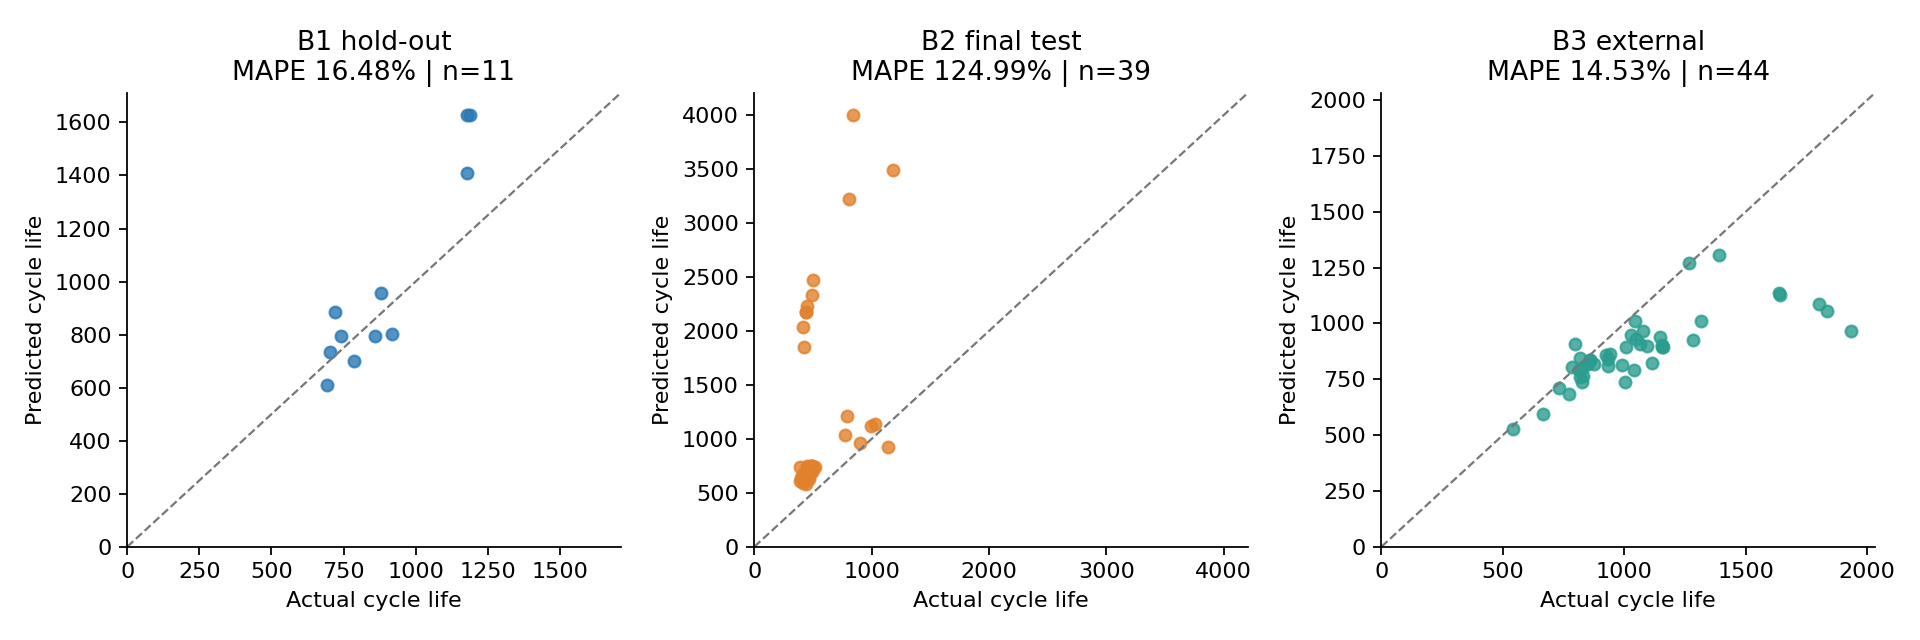

In [4]:
display(performance.round(3))
display(pd.read_csv(ROOT / 'results/evaluation_metrics.csv').round(3))
stats = make_figures(ROOT)
display(stats.round(1))
display(Image(filename=str(ROOT / 'results/figures/02_model_comparison.png')))
display(Image(filename=str(ROOT / 'results/figures/03_actual_vs_predicted.png')))

## 4. 배치 차이와 오류 분석
아래 그림은 고정된 모델을 평가한 후의 해석 자료입니다. 이 결과로 모델·피처·임계치를 다시 조정하지 않습니다.
작은 배치의 평균 오차는 소수 셀에 크게 영향을 받을 수 있습니다. 과대예측은 수명이 충분하다는 잘못된 판단으로 이어질 수 있어 특히 살펴봅니다.


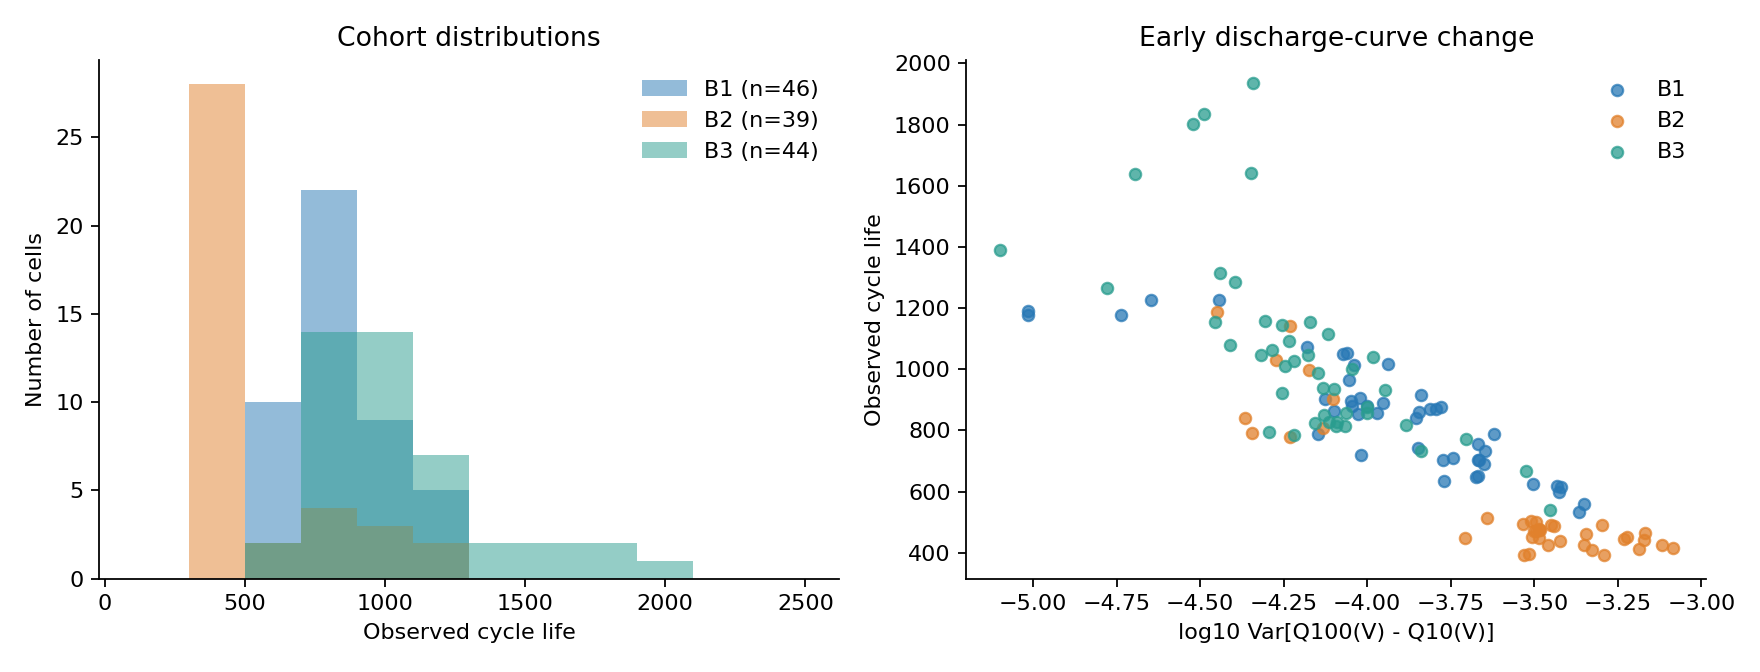

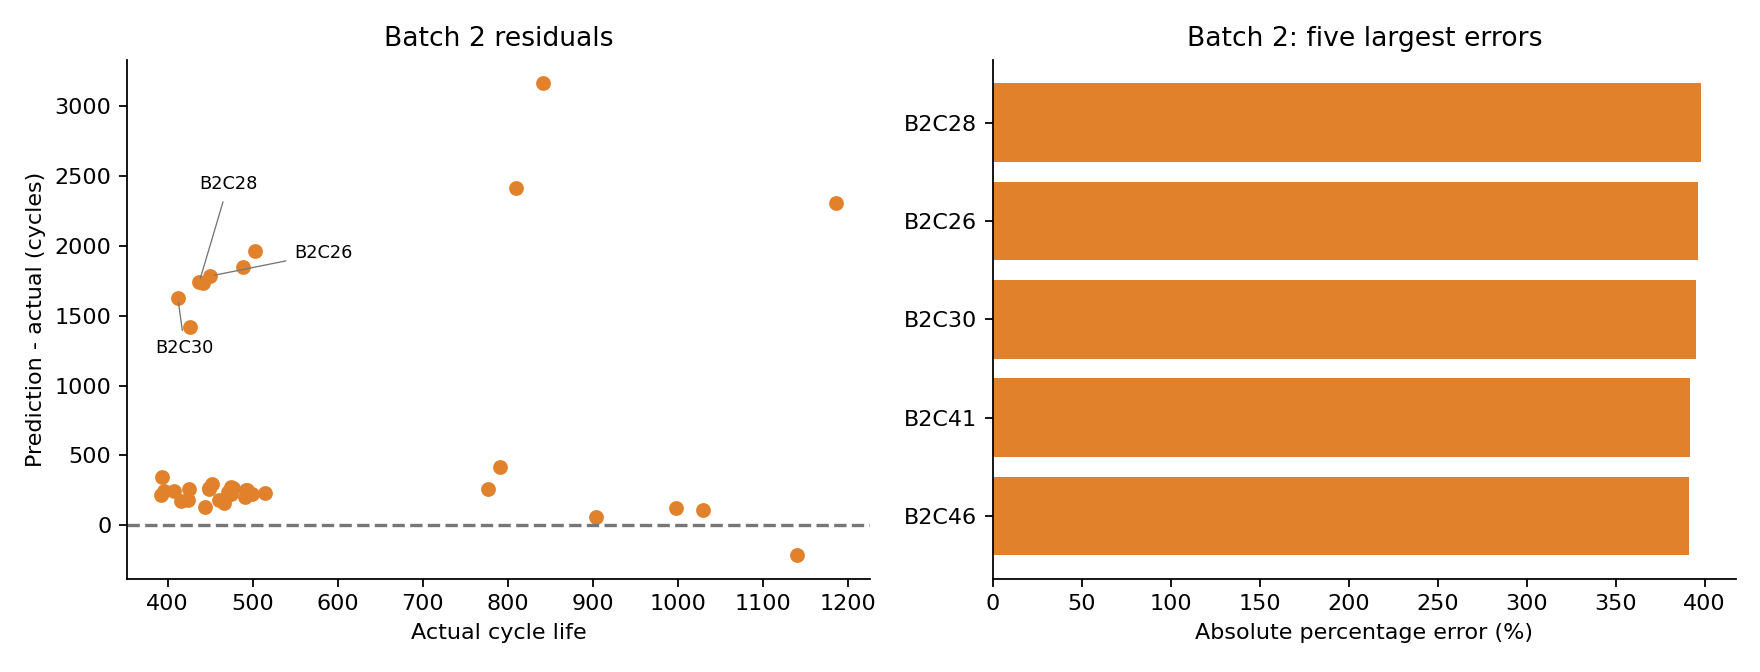

,cell_uid,batch,policy_group,cycle_life,split,prediction,residual,APE_pct
0,B2C28,B2,4.8C(80%)-4.8C,437.0,Test (Batch 2),2175.400,1738.400,397.803
1,B2C26,B2,5.6C(26%)-4.5C,450.0,Test (Batch 2),2233.933,1783.933,396.430
2,B2C30,B2,5.6C(26%)-4.5C,412.0,Test (Batch 2),2039.792,1627.792,395.095
3,B2C41,B2,5.6C(26%)-4.5C,442.0,Test (Batch 2),2174.388,1732.388,391.943
4,B2C46,B2,4.8C(80%)-4.8C,503.0,Test (Batch 2),2469.734,1966.734,391.001


,cell_uid,cycle_life,log_dq_var,policy_group,outside_B1_train_logdq_range,APE_pct
26,B2C28,437.0,-3.423,4.8C(80%)-4.8C,False,397.803
24,B2C26,450.0,-3.222,5.6C(26%)-4.5C,True,396.430
28,B2C30,412.0,-3.185,5.6C(26%)-4.5C,True,395.095
33,B2C41,442.0,-3.172,5.6C(26%)-4.5C,True,391.943
38,B2C46,503.0,-3.509,4.8C(80%)-4.8C,False,391.001


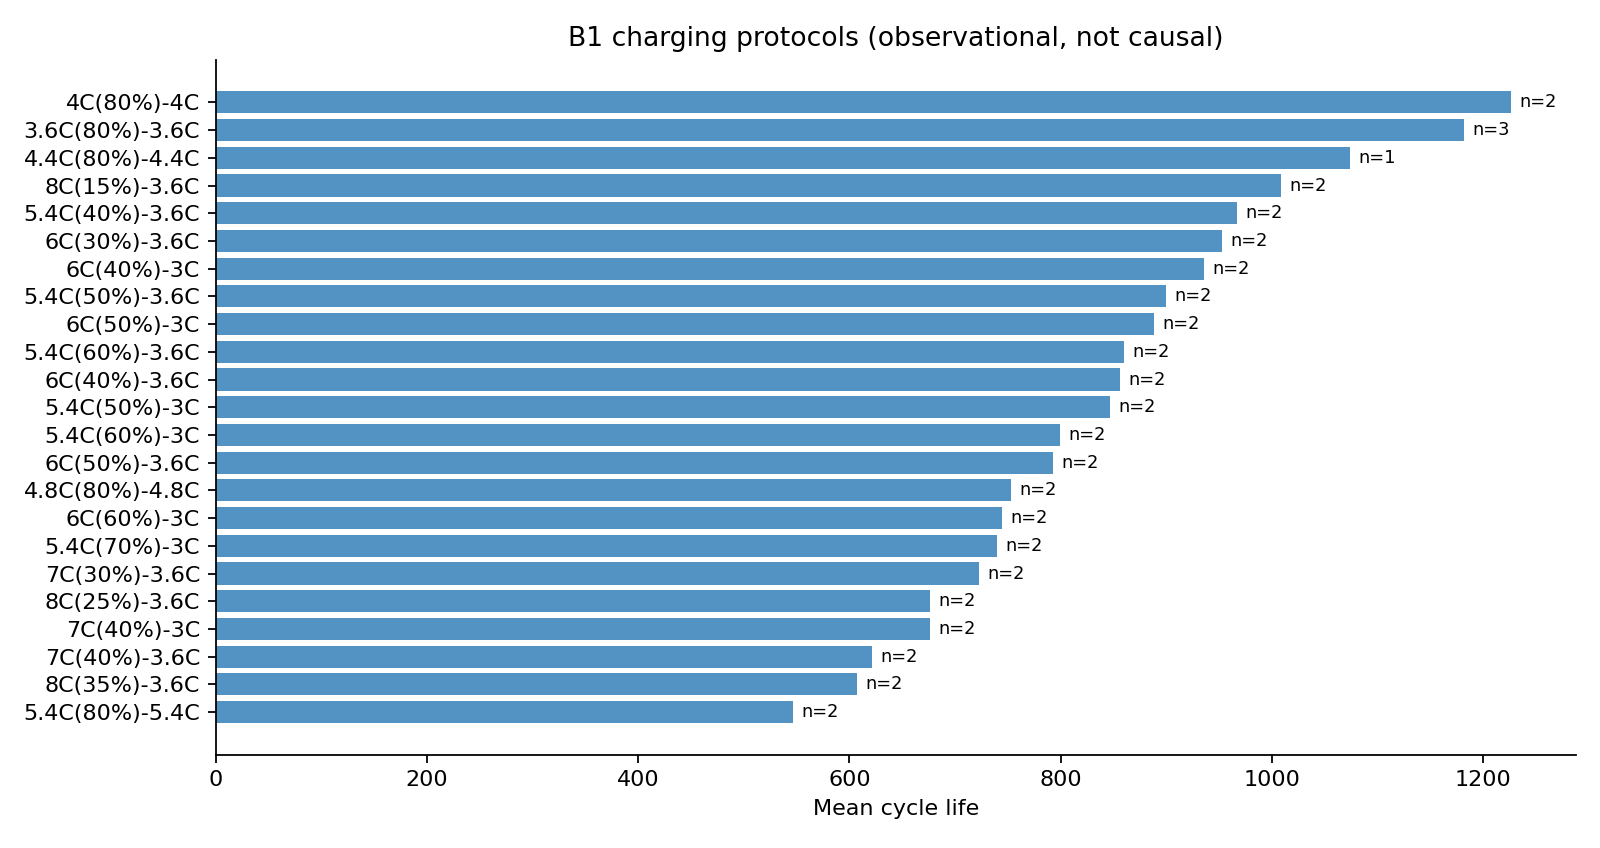

In [5]:
display(Image(filename=str(ROOT / 'results/figures/01_data_overview.png')))
display(Image(filename=str(ROOT / 'results/figures/04_error_analysis.png')))
display(pd.read_csv(ROOT / 'results/largest_errors_batch2.csv').round(3))
error_features = pd.read_csv(ROOT / 'results/batch2_error_features.csv')
display(error_features.nlargest(5, 'APE_pct')[
    ['cell_uid','cycle_life','log_dq_var','policy_group','outside_B1_train_logdq_range','APE_pct']].round(3))
display(Image(filename=str(ROOT / 'results/figures/05_charging_policy.png')))

## 5. 일반화 실패의 진단
선택 모델의 CV 점수가 좋더라도 B2 성능이 좋다는 보장은 없습니다.
학습 범위를 벗어난 피처와 선형 계수의 기여를 확인합니다.
기존 후보 중 하이퍼파라미터가 없는 두 기준 모델도 비교합니다. 이 비교는 최종 모델을 바꾸기 위한 재튜닝이 아닙니다.
B2를 이미 확인했으므로, 이후 개선 모델을 선택한다면 새로운 독립 평가셋이 필요합니다.


,model,split,n,MAPE_pct,MAE_cycles,RMSE_cycles,R2
0,DummyMedian,B1_valid,11,16.488,154.818,192.923,-0.041
1,DummyMedian,B2_test,39,72.400,341.051,364.606,-1.763
2,DummyMedian,B3_external,44,20.232,251.341,370.602,-0.427
3,LogLinear_DeltaQ,B1_valid,11,18.203,185.905,268.324,-1.013
4,LogLinear_DeltaQ,B2_test,39,28.864,144.110,163.064,0.447
5,LogLinear_DeltaQ,B3_external,44,12.595,150.186,230.835,0.447


,feature,batch,train_min,train_max,external_min,external_max,outside_train_range_n,n
0,log_dq_var,B2,-4.6477,-3.3503,-4.4486,-3.0859,11,39
2,log_abs_dq_min,B2,-1.8552,-1.1890,-1.7180,-1.0647,9,39
4,qd_slope,B2,-0.0001,0.0000,-0.0002,0.0001,19,39
6,ir_mean,B2,0.0151,0.0174,0.0148,0.0177,8,39
8,charge_mean,B2,8.9873,15.0758,10.0358,49.8795,10,39
10,qd_initial,B2,1.0556,1.0964,1.0677,1.1101,20,39
12,qd_delta,B2,-0.0125,0.0050,-0.0199,0.0132,12,39
14,ir_delta,B2,-0.0004,0.0002,-0.0009,0.0003,12,39
16,temp_mean,B2,29.9422,33.8950,29.8815,35.6679,6,39
18,c1,B2,4.0000,8.0000,3.6000,6.0000,4,39


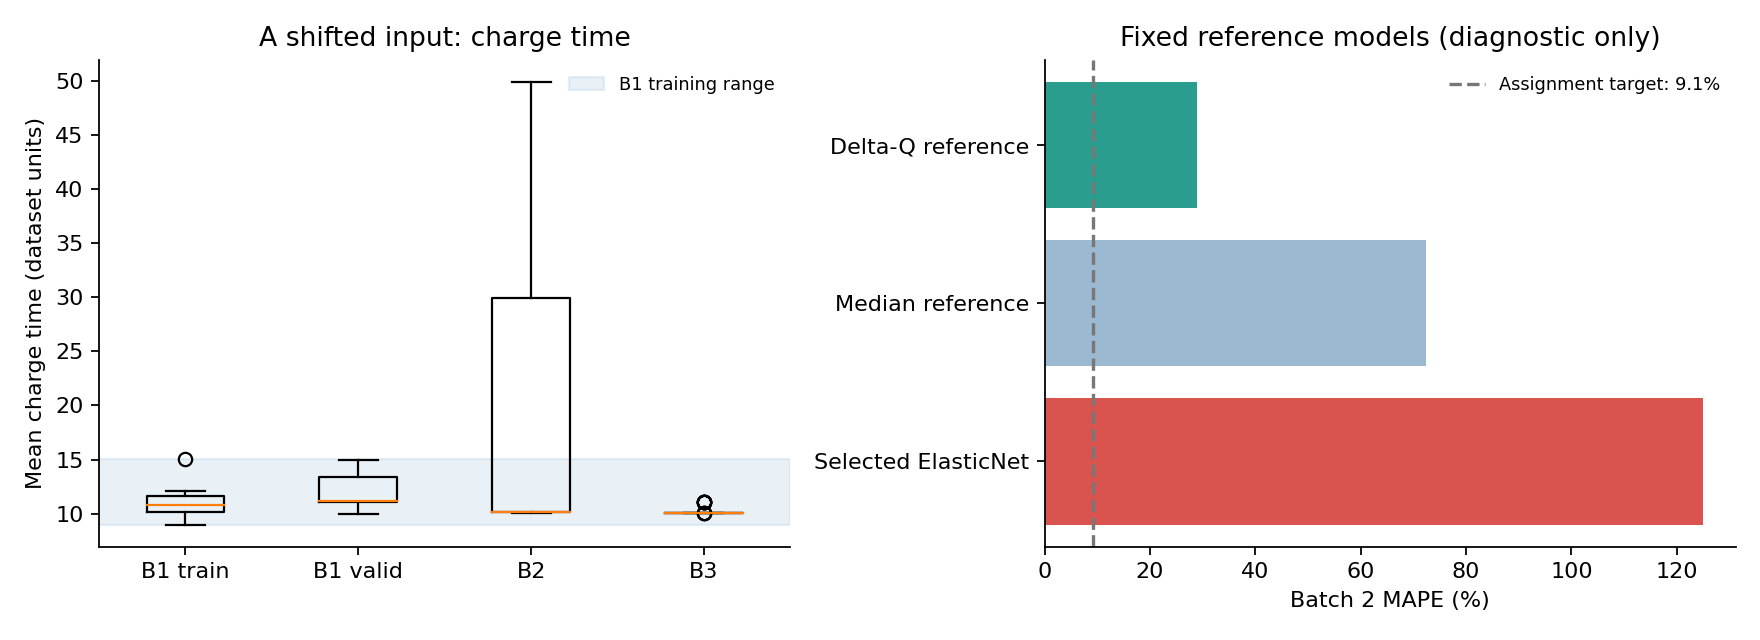

**결론:** 선택 모델의 B2 MAPE는 124.99%로 과제 목표 9.1%보다 115.89 pp 높아 목표를 달성하지 못했습니다. 충전 시간의 B1 학습 범위는 8.99–15.08인데 B2 최대값은 49.88이며, 10셀이 범위 밖입니다. 입력 분포 차이가 큰 과대예측에 기여했습니다. 측정 정의의 차이인지 실제 운전 차이인지는 추가 확인이 필요합니다. CV 선택 모델은 유지하며, 이 모델을 현장 운영에 채택할 수는 없습니다.

In [6]:
references, shift = diagnose(ROOT)
display(references.round(3))
display(shift.query("batch == 'B2'").round(4))
display(Image(filename=str(ROOT / 'results/figures/06_shift_and_references.png')))
charge_shift = shift.query("batch == 'B2' and feature == 'charge_mean'").iloc[0]
display(Markdown(
    f"**결론:** 선택 모델의 B2 MAPE는 {summary['test_mape']:.2f}%로 "
    f"과제 목표 9.1%보다 {summary['gap_target_test']:.2f} pp 높아 목표를 달성하지 못했습니다. "
    f"충전 시간의 B1 학습 범위는 {charge_shift.train_min:.2f}–{charge_shift.train_max:.2f}인데 "
    f"B2 최대값은 {charge_shift.external_max:.2f}이며, {int(charge_shift.outside_train_range_n)}셀이 범위 밖입니다. "
    "입력 분포 차이가 큰 과대예측에 기여했습니다. 측정 정의의 차이인지 실제 운전 차이인지는 추가 확인이 필요합니다. "
    "CV 선택 모델은 유지하며, 이 모델을 현장 운영에 채택할 수는 없습니다."))

## 6. 저장 모델 재사용과 재현 확인
피처 순서는 저장된 모델의 `features`를 따릅니다. 모델 파일은 이 프로젝트에서 생성한 파일만 사용합니다.


In [7]:
import joblib
artifact = joblib.load(ROOT / 'results/final_model.joblib')
test = features.query("batch == 'B2'")
reloaded_pred = artifact['model'].predict(test[artifact['features']])
saved_pred = pd.read_csv(ROOT / 'results/predictions.csv').query("batch == 'B2'").prediction
np.testing.assert_allclose(reloaded_pred, saved_pred, rtol=1e-10)
splits = pd.read_csv(ROOT / 'results/split_assignments.csv')
tr = splits.query("split == 'B1_train'")
va = splits.query("split == 'B1_valid'")
assert set(tr.policy_group).isdisjoint(va.policy_group)
assert set(tr.cell_uid).isdisjoint(va.cell_uid)
assert set(summary['features']).issubset(set(EXTENDED))
assert set(summary['trained_on']).isdisjoint(set(test.cell_uid))
print('저장 모델 예측 일치 / 셀·정책 분리 / 테스트 학습 제외 확인 완료')

저장 모델 예측 일치 / 셀·정책 분리 / 테스트 학습 제외 확인 완료


## 7. ESS 운영 관점
초기 운전 데이터로 열화 위험 후보를 선별해 점검 우선순위와 예비품 계획을 세우는 보조 신호로 활용할 수 있습니다.
현재 타깃은 전체 수명입니다. 100사이클 시점 RUL 추정은 `예측 수명−100`이지만 직접 검증한 별도 RUL 모델은 아닙니다.
단일 실험 셀, 제한된 온도·충전 프로토콜, 작은 표본이라는 한계가 있습니다.
실제 BESS에는 현장 데이터 외부 검증, 온도·휴지·달력 열화 반영, 불확실성 구간과 보수적 점검 기준이 필요합니다.
수명 예측 모델은 화재 진단이나 안전 보증 모델이 아닙니다.

**참고:** [과제 안내](https://actually-war-1ea.notion.site/DS-Mini-Project-32d7f4c8669380338a27f90c471c1fcb),
[Severson et al. (2019)](https://doi.org/10.1038/s41560-019-0356-8),
[저자 데이터 처리 코드](https://github.com/rdbraatz/data-driven-prediction-of-battery-cycle-life-before-capacity-degradation).
